In [2]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor 
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression,SGDClassifier
from sklearn.preprocessing import PolynomialFeatures,StandardScaler,OneHotEncoder
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax # expit:이진분류함수, softmax:다중분류 함수 0-1숫자로 변환
import numpy as np
from io import StringIO

In [3]:
# 레드와인, 화이트와인을 분류하는 알고라즘을 구현하시오
# LogisticRegression 사용 - ridge 규제를 사용해서 구현 04
# SGDClassifier 사용 - 반복 300회 해서 구현 05
# 두가지 모델을 사용해서 구현하시오
# 이 확률로 이 와인이다

In [4]:
# 데이터 전처리
df = pd.read_csv('data/wine.csv')
df
label = df['class'].values # 0레드, 1화이트
data = df[df.columns[:-1]].values
data,label

(array([[ 9.4 ,  1.9 ,  3.51],
        [ 9.8 ,  2.6 ,  3.2 ],
        [ 9.8 ,  2.3 ,  3.26],
        ...,
        [ 9.4 ,  1.2 ,  2.99],
        [12.8 ,  1.1 ,  3.34],
        [11.8 ,  0.8 ,  3.26]], shape=(6497, 3)),
 array([0., 0., 0., ..., 1., 1., 1.], shape=(6497,)))

In [5]:
# 데이터 분류
train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)


In [6]:
# 정규화
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)


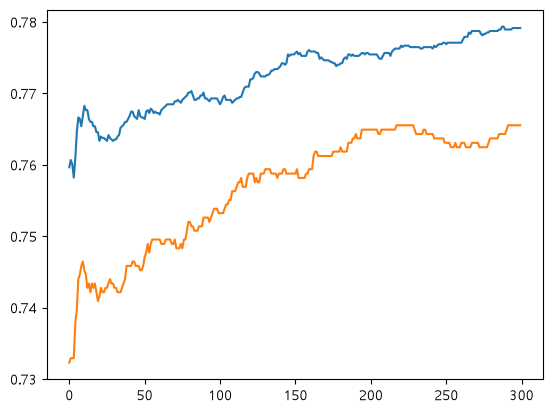

In [10]:
sc = SGDClassifier(loss='log_loss',random_state=42)
train_score = []
test_score = []


classes = np.unique(train_label)


for i in range(300):
    sc.partial_fit(train_scaled,train_label,classes=classes)
    train_score.append(sc.score(train_scaled,train_label))
    test_score.append(sc.score(test_scaled,test_label))

plt.plot(train_score)
plt.plot(test_score)
plt.show()

In [18]:
sc = SGDClassifier(loss='log_loss',max_iter=300,tol=None,random_state=42)
sc.fit(train_scaled,train_label)
print('train_정확도',sc.score(train_scaled,train_label))
print('test_정확도',sc.score(test_scaled,test_label))

# in_data = '9.4,1.9,3.51'
in_data = '9.8,2.6,3.2'
in_data = list(map(float,in_data.split(',')))
in_data = ss.transform([in_data])
# result = []
predict = sc.predict(in_data)

if predict[0] =='1.0':
    name ='화이트와인'
else:
    name = '레드와인'
        
predict1 = sc.predict_proba(in_data)
predict2=predict1.max()

print(f'{predict2*100:.2f}% 확률로 {name}이다.')
predict1

train_정확도 0.7820197044334976
test_정확도 0.7661538461538462
64.37% 확률로 레드와인이다.


array([[0.35625872, 0.64374128]])